In [31]:
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
# Load dataset from data preprocessing csv
dataset = pd.read_csv("./datasets/PreProcessedDataset.csv")

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, pCR (outcome) to IsoForest_Outlier
dtypes: float64(120), int64(1)
memory usage: 378.2 KB


# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis, idk what else slides say


Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 


First do Correlation analysis for visualisation: https://www.geeksforgeeks.org/machine-learning/data-preprocessing-machine-learning-python/#:~:text=Step%205%3A%20Correlation%20Analysis

- Also other methods in lab probably

In [ ]:
# Preserve important features
dataset_preserve = dataset[['Gene','ER','HER2']]
dataset = dataset.drop(labels=['Gene', 'ER', 'HER2'], axis=1)


# Split data into features and outcomes

## Outcomes
dataset_y_clf = dataset['pCR (outcome)']
datasey_y_reg = dataset['RelapseFreeSurvival (outcome)']

## Features
dataset_x_all = dataset.drop(['pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis=1)

dataset_x_all

,Age,PgR,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,original_shape_Elongation,original_shape_Flatness,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,IsoForest_Outlier
0,0.318004,0.0,1.0,3.0,3.0,1.0,1.0,2.0,0.797297,0.807835,...,0.437647,0.672134,0.204145,0.000279,0.022801,5.200670e-10,0.640530,0.502250,0.000661,1
1,0.282670,1.0,0.0,3.0,3.0,1.0,1.0,2.0,0.622626,0.487408,...,0.518456,0.612873,0.496269,0.000171,0.002864,4.135234e-09,0.112285,0.016557,0.003217,1
2,0.141335,0.0,1.0,2.0,1.0,1.0,0.0,2.0,0.597765,0.640311,...,0.623641,0.502453,0.597166,0.000111,0.001634,7.336077e-09,0.084398,0.008716,0.005628,1
3,0.212003,0.0,1.0,3.0,3.0,1.0,1.0,3.0,0.746394,0.519793,...,0.590549,0.526790,0.331763,0.000499,0.002257,5.176563e-09,0.048078,0.002923,0.003966,1
4,0.671342,0.0,0.0,2.0,1.0,1.0,0.0,2.0,0.852989,0.841683,...,0.539329,0.567826,0.576747,0.000091,0.001908,6.337420e-09,0.119775,0.017836,0.004911,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.627175,0.0,0.0,3.0,2.0,1.0,1.0,4.0,0.295630,0.222072,...,0.555908,0.495931,0.285167,0.000167,0.000894,1.351774e-08,0.063282,0.004736,0.010699,1
396,0.199636,0.0,1.0,3.0,3.0,1.0,0.0,2.0,0.917529,0.811094,...,0.488113,0.605487,0.375002,0.000072,0.007543,1.980464e-09,0.477078,0.364630,0.001832,1
397,0.535307,0.0,1.0,2.0,1.0,1.0,0.0,2.0,0.612128,0.449973,...,0.615741,0.303188,0.329379,0.000015,0.000048,2.523337e-07,0.025884,0.000616,0.201692,1
398,0.809144,0.0,0.0,3.0,3.0,1.0,1.0,3.0,0.887548,0.954371,...,0.365975,0.722306,0.097768,0.001445,0.009866,1.123983e-09,0.189627,0.060858,0.001194,1


### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



##### Embedded Methods
Embed Feature Selection into the model process. Should probably use in the ML Method Development process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

In [ ]:
# Further split Features into Categorical and Continuous
    # Features should be converted back to their initial type after null handling

dataset_x_categorical
dataset_x_continuous

t-test requirements:
- Gaussian Distribution: data is close to gaussian distribution
- Binary Features: data contains binary features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

chi-square requirements:
- Categorical Features: dataset contains categorical features
- Categorical Outcome: pCR (outcome) is the categorical outcome

Conclusion: Applicable, features would need to be split

ANOVA requirements:
- Categorical Features: dataset contains categorical features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the categorical outome

Conclusion: Applicable, features would need to be split

Correlation Analysis requirements:
- Continuous Feature: dataset contains continuous features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)
Xs_pca = pca.fit_transform(dataset_x_all)
PCA_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])

PCA_df

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10
0,-2.590303,1.079915,0.451506,-0.292130,0.069280,0.384540,0.527531,-0.498500,0.010367,0.283991
1,0.013835,1.276261,-0.741521,0.366816,1.166545,0.570812,-0.102248,0.314548,-0.274965,-0.026483
2,0.295017,-0.240512,-1.095653,0.434405,-0.502482,-0.986244,0.157179,0.084774,0.203128,-0.297313
3,0.719833,1.992713,-0.336673,0.279858,0.033157,-0.054564,0.577263,0.117705,0.049459,0.048773
4,0.107728,-0.490266,-0.887752,0.448131,0.142926,-0.843972,-0.060552,-0.061364,0.206618,-0.452074
...,...,...,...,...,...,...,...,...,...,...
395,1.333029,1.081803,0.563198,0.273128,0.097733,0.254035,0.404926,-0.189355,0.520687,0.009404
396,-2.373929,1.081241,0.333032,-0.224669,-0.332562,0.020136,-0.326191,0.240293,0.206727,0.247751
397,0.544278,-0.459986,-1.397297,0.205972,-1.386851,0.259847,-0.061434,-0.232993,0.666011,-0.146732
398,-0.278304,1.614250,0.434275,-0.201993,0.652543,-0.073105,0.238717,-0.518907,-0.249596,0.442483


Plotting PCA Features

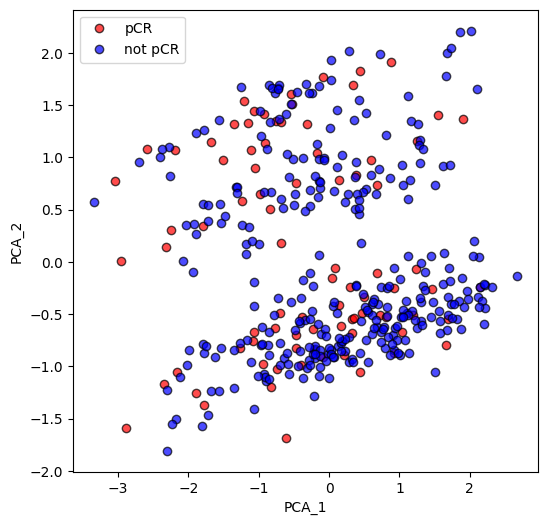

In [35]:
plt.figure(figsize=(6,6))
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 1], PCA_df['PCA_2'][dataset_y_clf == 1], 'ro', alpha = 0.7, markeredgecolor = 'k')
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 0], PCA_df['PCA_2'][dataset_y_clf == 0], 'bo', alpha = 0.7, markeredgecolor = 'k')
plt.xlabel('PCA_1')
plt.ylabel('PCA_2')
plt.legend(['pCR','not pCR'])

##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA()
lda.fit(X = dataset_x_all, y = dataset_y_clf)

lda.predict(X=[dataset_x_all.loc[1]])

C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


array([0.])

In [ ]:
# Must remember to reconstruct format for original dataset
    # Make a new dataset that adds features (columns in their original order)
dataset.to_csv("./datasets/FeatureSelectedDataset.csv",index=False)